# Round 2: relation types in detail, and two new variants

Round 1 (`coco_mlt_relation_contrastive_fast.ipynb`) was the main test,
with rules set before running. This notebook does three things:

1. **By-type breakdown (no training).** Splits the tail classes' false
   positives by relation type (related & seen together, related &
   never together, informative companion, generic companion) for every
   method, using the predictions round 1 saved. It shows *where* each
   method reduces or adds confusion.
2. **Two new variants**, trained exactly like round 1 (settings chosen
   on the dev set with seed 42, then seeds 43 and 44):
   - **Ours, stronger weights:** alpha 8 or 16. Round 1 tried 1 and 4,
     and dev mAP rose with alpha.
   - **Ours x SCHaNe:** each negative's weight is SCHaNe's similarity
     weight times our relation weight (temperature 0.5, SCHaNe's
     chosen setting; alpha 1 or 4). SCHaNe raised overall mAP but added
     related-class confusion; ours did the opposite.
3. **Exploratory verdicts** for the new variants against MulSupCon,
   with the same rules as round 1.

**Round 2 is exploratory.** These ideas come after seeing round 1's
results, so a gain here is a hypothesis to confirm (ideally on a second
dataset), and every variant tried should be reported alongside round 1.

## Step 0: setup

In [1]:
import glob
import hashlib
import importlib
import json
import os
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display

if not os.path.exists("context_reliance_check.py"):
    raise SystemExit("Put context_reliance_check.py in the same folder "
                     "as this notebook.")
import context_reliance_check as crc
importlib.reload(crc)
if not hasattr(crc, "related_labels"):
    raise SystemExit("context_reliance_check.py is an older version. "
                     "Replace it with the latest one.")
pd.set_option("display.max_colwidth", None)    # show full table cells
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"numpy {np.__version__}, pandas {pd.__version__}, "
      f"torch {torch.__version__}")
if DEVICE == "cuda":
    props = torch.cuda.get_device_properties(0)
    print(f"Device: {props.name} ({props.total_memory / 2**30:.1f} GB)")
else:
    print(f"Device: CPU (this PyTorch build has CUDA: {torch.version.cuda})")

numpy 2.5.4, pandas 3.1.0, torch 2.11.0+cu130
Device: NVIDIA GeForce RTX 4070 Laptop GPU (8.0 GB)


## Step 1: settings

In [2]:
DATA = "coco_mlt"
OUT = os.path.join(DATA, "contrastive")      # same folder as round 1
SEEDS = [42, 43, 44]
SELECT_SEED = 42
DEV_FRAC = 0.2
SPLIT_SEED = 0
RELATED_PCT = 5
BOOTSTRAP = 10000
RETRAIN = False           # True reruns everything, ignoring saved runs
WORKERS = "auto"          # trainings at the same time ("auto" or a number)
ALLOW_CPU = False
QUICK_TEST = False        # True = tiny run to test the code only

# Round 1 variants: identical to round 1, so its saved runs are reused
VARIANTS = [
    ("bce", "BCE (no pretraining)", "bce", [dict(lrp=0.1), dict(lrp=1.0)]),
    ("mulsupcon", "MulSupCon", "uniform", [dict()]),
    ("ours", "MulSupCon + selective relation weights (ours)", "relation",
     [dict(alpha=1.0), dict(alpha=4.0)]),
    ("companions", "MulSupCon + all-companion weights", "companions",
     [dict(alpha=1.0), dict(alpha=4.0)]),
    ("schane", "MulSupCon + SCHaNe weights", "schane",
     [dict(tau=0.1), dict(tau=0.5)]),
    ("lcl", "MulSupCon + LCL weights", "lcl", [dict(tau=0.1), dict(tau=0.3)]),
    ("relbce", "BCE + selective relation weights (no contrast)", "relbce",
     [dict(alpha=a, lrp=l) for a in (1.0, 4.0) for l in (0.1, 1.0)]),
    # Round 2 (exploratory)
    ("ours_strong", "Ours with stronger weights (round 2)", "relation",
     [dict(alpha=8.0), dict(alpha=16.0)]),
    ("ours_schane", "Ours x SCHaNe weights (round 2)", "relation_schane",
     [dict(alpha=1.0, tau=0.5), dict(alpha=4.0, tau=0.5)]),
]
ROUND2 = ["ours_strong", "ours_schane"]
NAME = {k: n for k, n, _, _ in VARIANTS}
SHORT = {"bce": "BCE", "mulsupcon": "MulSupCon", "ours": "Ours",
         "companions": "All companions", "schane": "SCHaNe", "lcl": "LCL",
         "relbce": "Relation BCE", "ours_strong": "Ours, stronger",
         "ours_schane": "Ours x SCHaNe"}


def setting_text(s):
    words = {"alpha": "alpha {:g}", "tau": "temperature {:g}",
             "lrp": "backbone lr x{:g}"}
    return ", ".join(words[k].format(v) for k, v in s.items()) or "-"


def setting_tag(s):
    return "-".join(f"{k}{v:g}" for k, v in s.items()) or "default"


if DEVICE == "cpu" and not (QUICK_TEST or ALLOW_CPU):
    raise SystemExit(
        "No GPU is visible to this notebook. In Jupyter or VS Code, pick the "
        "kernel (Python environment) you used for round 1, then Restart & "
        "Run All. (To run on the CPU anyway, set ALLOW_CPU = True.)")
for sub in ("runs", "backbones", "logs"):
    os.makedirs(os.path.join(OUT, sub), exist_ok=True)
pd.DataFrame([("2" if k in ROUND2 else "1", n, kind,
               " / ".join(setting_text(s) for s in grid))
              for k, n, kind, grid in VARIANTS],
             columns=["round", "variant", "kind", "settings tried"])

,round,variant,kind,settings tried
0,1,BCE (no pretraining),bce,backbone lr x0.1 / backbone lr x1
1,1,MulSupCon,uniform,-
2,1,MulSupCon + selective relation weights (ours),relation,alpha 1 / alpha 4
3,1,MulSupCon + all-companion weights,companions,alpha 1 / alpha 4
4,1,MulSupCon + SCHaNe weights,schane,temperature 0.1 / temperature 0.5
5,1,MulSupCon + LCL weights,lcl,temperature 0.1 / temperature 0.3
6,1,BCE + selective relation weights (no contrast),relbce,"alpha 1, backbone lr x0.1 / alpha 1, backbone lr x1 / alpha 4, backbone lr x0.1 / alpha 4, backbone lr x1"
7,2,Ours with stronger weights (round 2),relation,alpha 8 / alpha 16
8,2,Ours x SCHaNe weights (round 2),relation_schane,"alpha 1, temperature 0.5 / alpha 4, temperature 0.5"


## Step 2: method code

The same code as round 1, plus one addition: the combined weighting
(`relation_schane`), where a negative's weight is SCHaNe's Eq. 3 weight
times our relation weight. Nothing else changed, so round 1's saved
runs stay valid. This cell saves the code as
`relation_contrastive_method.py`.

In [3]:
%%writefile relation_contrastive_method.py
# ---------------------------------------------------------------------------
# Core code for the relation-aware contrastive experiment (frozen CLIP features)
#
# MulSupCon follows the official implementation (Zhang & Wu, AAAI 2024,
# github: MulSupCon, vector-data configuration): MLP backbone, projection
# head, MoCo-style momentum key encoder and queue, MulSupCon positives (each
# label of an anchor separately), WeightedSupCon loss with 1/len(rows)
# weights, 50% feature masking, Adam + cosine warm restarts, then fine-tuning
# with BCE (backbone lr x0.1, ReduceLROnPlateau, early stopping on a dev set).
# The other variants change only how negatives are weighted inside that loss.
#
# SCHaNe (Long et al. 2023) and LCL (Suresh & Ong 2021) have no official code
# for this setting; their weights are implemented from the papers' equations:
#   SCHaNe Eq. 3: negative k of anchor i gets
#                 beta_k = |N| exp(s_ik/tau) / sum_{n in N} exp(s_in/tau)
#   LCL Eq. 3:    every term of anchor i is weighted by w_{i, y_a}, the
#                 anchor's weighting-network probability for candidate a's
#                 class (w_{i, y_i} for positives, numerator included).
#                 Multi-label adaptation: sigmoid probabilities (BCE-trained
#                 weighting network) and, for a negative with several labels,
#                 the largest of the anchor's probabilities for those labels.
# ---------------------------------------------------------------------------
import copy
import math
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

CODE_VERSION = "2026-10-30"     # part of the saved-run tag (unchanged: same computation)

# Official settings (codes/config/pretrain_yeast.yaml and train_yeast.yaml)
PRETRAIN = dict(epochs=150, iters_per_epoch=1000, batch_size=64, cap_Q=256,
                momentum=0.999, temperature=0.1, out_dim=256, n_hidden=1,
                lr=4e-4, weight_decay=1e-5, T_0=50, T_mult=2, eta_min=1e-4,
                mask_p=0.5, running_alpha=0.98)
# Fine-tuning: official rules (BCE, Adam, backbone lr x0.1, ReduceLROnPlateau,
# early stopping after 20 epochs without a lower dev loss, test predictions
# at the lowest dev loss). One change: the official cap of 30 epochs (set for
# the 14-label yeast data) is raised to max_epochs so that early stopping,
# not the cap, ends training. The official-cap result is read from the same
# run (its first 30 epochs are identical) and reported as a secondary check.
FINETUNE = dict(official_epochs=30, max_epochs=400, iters_per_epoch=50,
                batch_size=32, lr=4e-4, lrp=0.1, plateau_factor=0.1,
                plateau_patience=2, plateau_cooldown=1, plateau_threshold=1e-3,
                early_stop_patience=20)


# --------------------------- data helpers ----------------------------------
def iterative_split(Y, test_frac, seed):
    """Iterative stratification for multi-label data (Sechidis et al., 2011).
    Returns 0 (fit) / 1 (dev) for each row, keeping every label's share close
    to the target in both parts."""
    rng = np.random.default_rng(seed)
    Y = np.asarray(Y, dtype=bool)
    n = Y.shape[0]
    frac = np.array([1.0 - test_frac, test_frac])
    desired = frac * n
    desired_label = np.outer(frac, Y.sum(0)).astype(float)
    remaining = np.ones(n, dtype=bool)
    assign = -np.ones(n, dtype=int)
    while True:
        rem = Y[remaining].sum(0)
        if rem.sum() == 0:
            break
        label = int(np.argmin(np.where(rem > 0, rem, np.iinfo(np.int64).max)))
        idx = np.flatnonzero(remaining & Y[:, label])
        rng.shuffle(idx)
        for i in idx:
            d = desired_label[:, label]
            cand = np.flatnonzero(d == d.max())
            if cand.size > 1:
                ds = desired[cand]
                cand = cand[ds == ds.max()]
            s = int(rng.choice(cand)) if cand.size > 1 else int(cand[0])
            assign[i] = s
            remaining[i] = False
            desired_label[s] -= Y[i]
            desired[s] -= 1
    for i in np.flatnonzero(remaining):          # images without labels
        s = int(np.argmax(desired))
        assign[i] = s
        desired[s] -= 1
    return assign


class Scaler:
    """sklearn.preprocessing.StandardScaler (population std, zero std -> 1)."""

    def fit(self, X):
        self.mean = X.mean(0)
        std = X.std(0)
        self.scale = np.where(std == 0, 1.0, std)
        return self

    def transform(self, X):
        return ((X - self.mean) / self.scale).astype(np.float32)


class OfficialSampler:
    """Batches exactly as the official RandomSampler: indices shuffled once
    by parse_data (RandomState(seed)), again by the sampler (RandomState(seed)),
    then read cyclically, reshuffling each time the pointer wraps."""

    def __init__(self, n, batch_size, seed):
        indices = list(range(n))
        np.random.RandomState(seed=seed).shuffle(indices)     # parse_data
        self.indices = np.array(indices)
        self.rs = np.random.RandomState(seed=seed)            # Sampler
        self.rs.shuffle(self.indices)
        self.ptr, self.batch_size = 0, batch_size

    def next(self):
        out = np.empty(self.batch_size, dtype=np.int64)
        for j in range(self.batch_size):
            out[j] = self.indices[self.ptr]
            self.ptr = (self.ptr + 1) % len(self.indices)
            if not self.ptr:
                self.rs.shuffle(self.indices)
        return out


def mask_views(x, p, generator):
    """Official vector augmentation: each feature kept with probability 1-p."""
    if not p:
        return x
    keep = (torch.rand(x.shape, generator=generator, device=x.device) > p)
    return x * keep.to(x.dtype)


# --------------------------- models (official) ------------------------------
class Backbone(nn.Module):
    """codes/backbone.py: MLP (vector data)."""

    def __init__(self, in_dim, dropout=0.2):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(in_dim, 256), nn.ReLU(), nn.Dropout(p=dropout),
            nn.Linear(256, 512), nn.ReLU(), nn.Dropout(p=dropout),
            nn.Linear(512, 256), nn.ReLU(), nn.Dropout(p=dropout))

    def forward(self, x):
        return self.mlp(x)


class ProjHead(nn.Module):
    """codes/models.py: MLP projection head."""

    def __init__(self, in_dim=256, out_dim=256, n_hidden=1):
        super().__init__()
        layers, d = [], in_dim
        for _ in range(n_hidden):
            nxt = d // 2 if d >= 2 * out_dim else out_dim
            layers += [nn.Linear(d, nxt), nn.BatchNorm1d(nxt), nn.ReLU(),
                       nn.Dropout(p=0.1)]
            d = nxt
        layers.append(nn.Linear(d, out_dim))
        self.mlp = nn.Sequential(*layers)

    def forward(self, x):
        return self.mlp(x)


class Encoder(nn.Module):
    def __init__(self, in_dim, out_dim=256, n_hidden=1):
        super().__init__()
        self.backbone = Backbone(in_dim)
        self.proj_head = ProjHead(256, out_dim, n_hidden)

    def forward(self, x):
        return self.proj_head(self.backbone(x))


class Classifier(nn.Module):
    """codes/models.py 'Simple': backbone + linear output layer."""

    def __init__(self, in_dim, n_class):
        super().__init__()
        self.backbone = Backbone(in_dim)
        self.output_layer = nn.Linear(256, n_class)

    def forward(self, x):
        return self.output_layer(self.backbone(x))


class PretrainModel(nn.Module):
    """codes/models.py PretrainModel (MoCo queue + momentum key encoder)."""

    def __init__(self, in_dim, n_class, cap_Q, momentum, out_dim, n_hidden):
        super().__init__()
        self.encoder_q = Encoder(in_dim, out_dim, n_hidden)
        self.encoder_k = Encoder(in_dim, out_dim, n_hidden)
        self.m, self.cap_Q = momentum, cap_Q
        self.register_buffer("QueuePtr", torch.tensor([0], dtype=torch.int32))
        self.register_buffer("QueueFull", torch.tensor([False]))
        self.register_buffer("MoCoQueue", nn.functional.normalize(
            torch.randn(out_dim, cap_Q), dim=0))
        self.register_buffer("LabelQueue", torch.zeros(cap_Q, n_class))
        for pq, pk in zip(self.encoder_q.parameters(),
                          self.encoder_k.parameters()):
            pk.data.copy_(pq.data)
            pk.requires_grad = False
        self._q = list(self.encoder_q.parameters())
        self._k = list(self.encoder_k.parameters())
        # Queue pointer and 'full' flag kept on the CPU as well, so no GPU
        # synchronisation is needed each step (same values as the buffers).
        self._ptr, self._full = 0, False

    @torch.no_grad()
    def momentum_update(self):
        torch._foreach_mul_(self._k, self.m)
        torch._foreach_add_(self._k, self._q, alpha=1 - self.m)

    def forward(self, x1, x2, labels):
        """Returns (scores, reference labels). Same order of operations as the
        official forward(): momentum update, queries, keys, clone of the
        queue, enqueue, then scores (batch keys only until the queue is
        full, then batch keys + queue)."""
        if self.training:
            self.momentum_update()
        q = nn.functional.normalize(self.encoder_q(x1), dim=1)
        with torch.no_grad():
            k = nn.functional.normalize(self.encoder_k(x2), dim=1)
        queue_k = self.MoCoQueue.clone().detach()
        queue_labels = self.LabelQueue.clone().detach()
        if self.training:
            B = len(labels)
            assert not self.cap_Q % B
            ptr = self._ptr
            self.MoCoQueue[:, ptr:ptr + B] = k.T
            self.LabelQueue[ptr:ptr + B] = labels
            ptr = (ptr + B) % self.cap_Q
            self._ptr = ptr
            self.QueuePtr.fill_(ptr)
            if not ptr:
                self._full = True
                self.QueueFull.fill_(True)
        batch_score = q @ k.T
        if not self._full:
            return batch_score, labels
        scores = torch.cat([batch_score, q @ queue_k], dim=1)
        ref_labels = torch.cat([labels, queue_labels], dim=0)
        return scores, ref_labels


# --------------------------- losses -----------------------------------------
def mulsupcon_loss(scores, batch_labels, ref_labels, tau, mode="uniform",
                   relation=None, alpha=0.0, p_anchor=None):
    """MulSupCon loss with optional negative weights.

    One row per (anchor image, anchor label k), in the official order
    (torch.where on the batch labels). Positives of a row: candidates that
    carry label k (the anchor's own key included). Loss per row:
        -(1/|P|) sum_p log( w_p e^{s_p/tau} / sum_a w_a e^{s_a/tau} )
    averaged over rows (official weights 1/len(rows)). With all w = 1 this is
    exactly the official MulSupCon/WeightedSupCon loss.

    mode:
      uniform    : w = 1 (MulSupCon)
      schane     : negatives w = |N| e^{s/tau} / sum_N e^{s/tau}
                   (Long et al. 2023, Eq. 3), positives 1
      lcl        : LCL Eq. 3 (Suresh & Ong 2021), weights from the anchor's
                   weighting-network probabilities p_anchor (B x C):
                   positives w = p_anchor[i, k] (numerator included),
                   negatives w = max over the candidate's labels c of
                   p_anchor[i, c]
      relation   : negatives w = 1 + alpha * max_c R[k, c] over the
                   candidate's labels c (relation given as list of
                   (value, mask matrix L x L)); positives 1
      relation_schane : negatives w = beta (SCHaNe, Eq. 3) x (1 + alpha *
                   max_c R[k, c]); positives 1 (round-2 combination)
    """
    img_idx, lab_idx = torch.where(batch_labels == 1)
    logits = scores[img_idx] / tau                        # R x Q
    pos = ref_labels[:, lab_idx].T > 0.5                  # R x Q
    n_pos = pos.sum(1)
    if mode == "uniform":
        log_prob = logits - torch.logsumexp(logits, dim=1, keepdim=True)
    else:
        if mode == "schane":
            masked = logits.masked_fill(pos, float("-inf"))
            n_neg = (~pos).sum(1, keepdim=True).clamp_min(1)
            log_beta = (masked - torch.logsumexp(masked, dim=1, keepdim=True)
                        + torch.log(n_neg.to(logits.dtype)))
            logw = torch.where(pos, torch.zeros_like(logits), log_beta)
        elif mode == "lcl":
            pa = p_anchor[img_idx]                                      # R x C
            w_pos = pa[torch.arange(len(lab_idx)), lab_idx].unsqueeze(1)  # R x 1
            w_cand = (pa.unsqueeze(1) * ref_labels.unsqueeze(0)).amax(2)  # R x Q
            w = torch.where(pos, w_pos.expand_as(logits), w_cand)
            logw = torch.log(w.clamp_min(1e-6))
        elif mode == "relation":
            score = torch.zeros_like(logits)
            refT = ref_labels.T                                         # C x Q
            for value, M in relation:
                has = (M[lab_idx] @ refT) > 0.5                         # R x Q
                score = torch.maximum(score, has.to(logits.dtype) * value)
            logw = torch.where(pos, torch.zeros_like(logits),
                               torch.log1p(alpha * score))
        elif mode == "relation_schane":
            masked = logits.masked_fill(pos, float("-inf"))
            n_neg = (~pos).sum(1, keepdim=True).clamp_min(1)
            log_beta = (masked - torch.logsumexp(masked, dim=1, keepdim=True)
                        + torch.log(n_neg.to(logits.dtype)))
            score = torch.zeros_like(logits)
            refT = ref_labels.T
            for value, M in relation:
                has = (M[lab_idx] @ refT) > 0.5
                score = torch.maximum(score, has.to(logits.dtype) * value)
            logw = torch.where(pos, torch.zeros_like(logits),
                               log_beta + torch.log1p(alpha * score))
        else:
            raise ValueError(mode)
        z = logits + logw
        log_prob = z - torch.logsumexp(z, dim=1, keepdim=True)
    per_row = -(log_prob * pos).sum(1) / n_pos
    return per_row.mean()


def mulsupcon_loss_vec(scores, batch_labels, ref_labels, tau, mode="uniform",
                       relation=None, alpha=0.0, p_anchor=None):
    """Same loss as mulsupcon_loss, computed for every (anchor, label) pair at
    once with fixed shapes (no data-dependent indexing, so no GPU sync).
    Rows whose label is absent from the anchor are computed and discarded.
    Shapes: scores B x Q, batch_labels B x C, ref_labels Q x C."""
    logits = scores / tau                                   # B x Q
    ref = ref_labels                                        # Q x C (0/1 float)
    refT = ref.T                                            # C x Q
    n_pos = ref.sum(0)                                      # C
    Yb = batch_labels                                       # B x C
    pos_sum = logits @ ref                                  # B x C: sum_p logit_p
    if mode == "uniform":
        den = torch.logsumexp(logits, dim=1, keepdim=True)  # B x 1
        row = -(pos_sum / n_pos.clamp_min(1) - den)         # B x C
    else:
        posmask = refT.unsqueeze(0) > 0.5                   # 1 x C x Q
        if mode == "relation":
            score = torch.zeros_like(refT)                  # C x Q
            for value, M in relation:
                has = (M @ refT) > 0.5                      # C x Q
                score = torch.maximum(score, has.to(logits.dtype) * value)
            lw = torch.where(refT > 0.5, torch.zeros_like(score),
                             torch.log1p(alpha * score))    # C x Q
            z = logits.unsqueeze(1) + lw.unsqueeze(0)       # B x C x Q
            pos_lw = 0.0
        elif mode == "schane":
            L3 = logits.unsqueeze(1).expand(-1, refT.shape[0], -1)
            # finite fill (not -inf) keeps gradients finite for rows without
            # negatives; exp(-1e4) is exactly 0 for the others
            neg_logits = L3.masked_fill(posmask, -1e4)
            n_neg = (refT < 0.5).sum(1).clamp_min(1).to(logits.dtype)  # C
            lse_neg = torch.logsumexp(neg_logits, dim=2, keepdim=True)
            log_beta = L3 - lse_neg + torch.log(n_neg).view(1, -1, 1)
            z = torch.where(posmask, L3, L3 + log_beta)
            pos_lw = 0.0
        elif mode == "relation_schane":
            L3 = logits.unsqueeze(1).expand(-1, refT.shape[0], -1)
            neg_logits = L3.masked_fill(posmask, -1e4)
            n_neg = (refT < 0.5).sum(1).clamp_min(1).to(logits.dtype)
            lse_neg = torch.logsumexp(neg_logits, dim=2, keepdim=True)
            log_beta = L3 - lse_neg + torch.log(n_neg).view(1, -1, 1)
            score = torch.zeros_like(refT)                  # C x Q
            for value, M in relation:
                has = (M @ refT) > 0.5
                score = torch.maximum(score, has.to(logits.dtype) * value)
            lw_rel = torch.log1p(alpha * score).unsqueeze(0)            # 1 x C x Q
            z = torch.where(posmask, L3, L3 + log_beta + lw_rel)
            pos_lw = 0.0
        elif mode == "lcl":
            lw_pos = torch.log(p_anchor.clamp_min(1e-6))               # B x C
            w_cand = (p_anchor.unsqueeze(1) * ref.unsqueeze(0)).amax(2)  # B x Q
            lw_neg = torch.log(w_cand.clamp_min(1e-6))                 # B x Q
            lw = torch.where(posmask, lw_pos.unsqueeze(2),
                             lw_neg.unsqueeze(1))                      # B x C x Q
            z = logits.unsqueeze(1) + lw
            pos_lw = lw_pos                                            # B x C
        else:
            raise ValueError(mode)
        den = torch.logsumexp(z, dim=2)                                # B x C
        row = -(pos_sum / n_pos.clamp_min(1) + pos_lw - den)
    keep = Yb > 0.5
    return (row * keep).sum() / keep.sum()


def relation_masks(sim, shared, n_train, n_images, related_fn, pct,
                   min_shared=2, lift_min=2.0):
    """Relation types for negative weights, from training labels only.
    Returns masks (L x L) for: related & seen together, related & never
    together, informative companion; plus 'any companion' (seen together)."""
    L = sim.shape[0]
    rel_seen = np.zeros((L, L), bool)
    rel_never = np.zeros((L, L), bool)
    informative = np.zeros((L, L), bool)
    companion = np.zeros((L, L), bool)
    base = n_train / n_images
    for t in range(L):
        related = related_fn(sim[t], t, pct)
        for c in range(L):
            if c == t:
                continue
            k = shared[t, c]
            if k >= 1:
                companion[t, c] = True
            if related[c]:
                (rel_seen if k >= 1 else rel_never)[t, c] = True
            elif k >= min_shared and n_train[t] and base[c]:
                if (k / n_train[t]) / base[c] >= lift_min:
                    informative[t, c] = True
    return rel_seen, rel_never, informative, companion


# --------------------------- official reference (for the self-test) ---------
def official_generate_output_MulSupCon(batch_labels, ref_labels, scores,
                                       with_weight=False):
    """Verbatim logic of codes/utils.py generate_output_MulSupCon."""
    B = len(batch_labels)
    indices = torch.where(batch_labels == 1)
    scores = scores[indices[0]]
    labels = torch.zeros(len(scores), batch_labels.shape[1], device=scores.device)
    labels[range(len(labels)), indices[1]] = 1
    masks = (labels @ ref_labels.T).to(torch.bool)
    n_score_per_sample = batch_labels.sum(dim=1).to(torch.int16).tolist()
    if with_weight:
        weights_per_sample = [1 / (n * B) for n in n_score_per_sample
                              for _ in range(n)]
    else:
        weights_per_sample = [1 / len(scores) for n in n_score_per_sample
                              for _ in range(n)]
    weights_per_sample = torch.tensor(weights_per_sample, device=scores.device,
                                      dtype=torch.float32)
    return scores, [masks.to(torch.long), weights_per_sample]


def official_weighted_supcon(score, ref, temperature=0.1):
    """Verbatim logic of codes/losses.py WeightedSupCon.forward."""
    mask, weight = ref
    num_pos = mask.sum(1)
    loss = - (torch.log((F.softmax(score / temperature, dim=1))) * mask).sum(1) \
        / num_pos
    return (loss * weight).sum()


# --------------------------- training ---------------------------------------
def set_seeds(seed):
    """As the official Runner: torch, numpy and CUDA seeds, deterministic cuDNN."""
    torch.manual_seed(seed)
    np.random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True


def pretrain(X, Y, mode, seed, device, cfg=PRETRAIN, relation=None, alpha=0.0,
             tau=None, report=None, epoch_hook=None):
    """Contrastive pretraining with the official MulSupCon schedule.
    X: scaled fit-split features (float tensor on device); Y: float labels.
    Returns the backbone weights at the lowest running training loss (the
    official 'train_best' checkpoint) and the loss history."""
    set_seeds(seed)
    tau = cfg["temperature"] if tau is None else tau
    N, D = X.shape
    C = Y.shape[1]
    gen = torch.Generator(device=device)
    gen.manual_seed(seed)
    model = PretrainModel(D, C, cfg["cap_Q"], cfg["momentum"], cfg["out_dim"],
                          cfg["n_hidden"]).to(device)
    groups = [{"params": model.encoder_q.backbone.parameters(), "lr": cfg["lr"]},
              {"params": model.encoder_q.proj_head.parameters(), "lr": cfg["lr"]}]
    weighting = None
    if mode == "lcl":
        # LCL weighting network: same architecture as the fine-tuning model,
        # trained with its own (here BCE) loss; only its probabilities are
        # used by the contrastive loss (detached).
        weighting = Classifier(D, C).to(device)
        groups.append({"params": weighting.parameters(), "lr": cfg["lr"]})
    opt = torch.optim.Adam(groups, lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
        opt, T_0=cfg["T_0"], T_mult=cfg["T_mult"], eta_min=cfg["eta_min"])
    sampler = OfficialSampler(N, cfg["batch_size"], seed)
    rel = None
    if relation is not None:
        rel = [(v, torch.as_tensor(m, dtype=torch.float32, device=device))
               for v, m in relation]
    best, best_state, history = math.inf, None, []
    t0 = time.time()
    for epoch in range(cfg["epochs"]):
        running = None        # ignite RunningAverage restarts every epoch
        model.train()
        if weighting is not None:
            weighting.train()
        # the epoch's batches, in the official sampler order, sent to the
        # device once (avoids a GPU synchronisation every iteration)
        batches = torch.from_numpy(np.stack(
            [sampler.next() for _ in range(cfg["iters_per_epoch"])])).to(device)
        for it in range(cfg["iters_per_epoch"]):
            idx = batches[it]
            x, y = X[idx], Y[idx]
            x1 = mask_views(x, cfg["mask_p"], gen)
            x2 = mask_views(x, cfg["mask_p"], gen)
            if mode == "lcl":
                logits_w = weighting(x1)                 # anchor's weighting output
                loss_w = F.binary_cross_entropy_with_logits(logits_w, y)
                p_anchor = torch.sigmoid(logits_w).detach()
                scores, ref = model(x1, x2, y)
                loss_c = mulsupcon_loss_vec(scores, y, ref, tau, "lcl",
                                            p_anchor=p_anchor)
                # LCL Eq. 6 with alpha = 0.5; the encoder's own classification
                # term L_e is left out (MulSupCon pretraining is contrastive
                # only; every variant is fine-tuned with BCE afterwards)
                loss = 0.5 * loss_w + 0.5 * loss_c
            else:
                scores, ref = model(x1, x2, y)
                loss = mulsupcon_loss_vec(scores, y, ref, tau, mode,
                                          relation=rel, alpha=alpha)
            opt.zero_grad()
            loss.backward()
            opt.step()
            v = loss.detach()
            running = v if running is None else \
                cfg["running_alpha"] * running + (1 - cfg["running_alpha"]) * v
        sched.step()
        r = float(running)
        if not math.isfinite(r):
            raise FloatingPointError(f"non-finite loss at epoch {epoch + 1}")
        history.append(r)
        if r < best:                       # official ModelCheckpoint 'train_best'
            best = r
            best_state = copy.deepcopy(model.encoder_q.backbone.state_dict())
        if report is not None and ((epoch + 1) % 25 == 0 or epoch == 0):
            report(f"    epoch {epoch + 1:>3}/{cfg['epochs']}: running loss {r:.4f} "
                   f"({time.time() - t0:.0f} s)")
        if epoch_hook is not None:          # lets a worker stop between epochs
            epoch_hook(epoch + 1)
    return best_state, history


def neg_weight_matrix(Ybin, masks, alpha):
    """Relation weights for BCE negatives: 1 + alpha x the largest relation
    value between the class (column) and any label of the image (row)."""
    score = np.zeros(Ybin.shape, dtype=np.float32)
    for value, M in masks:
        has = (Ybin.astype(np.float32) @ M.T.astype(np.float32)) > 0.5
        score = np.maximum(score, value * has)
    return 1.0 + alpha * score


def weighted_bce(logits, y, neg_weights=None):
    """BCEWithLogitsLoss (mean); optional weights on the negative terms."""
    if neg_weights is None:
        return F.binary_cross_entropy_with_logits(logits, y)
    w = torch.where(y > 0.5, torch.ones_like(neg_weights), neg_weights)
    return F.binary_cross_entropy_with_logits(logits, y, weight=w)


def finetune(Xfit, Yfit, Xdev, Ydev, Xtest, seed, device, cfg=FINETUNE,
             backbone_state=None, w_fit=None, w_dev=None, epoch_hook=None):
    """Official 'train' stage: backbone (pretrained or random) + linear layer,
    BCE, Adam (backbone lr x lrp), ReduceLROnPlateau and early stopping on the
    dev loss; test predictions taken at the best dev loss.

    Returns (main, official). Training runs until early stopping or
    cfg['max_epochs']; 'main' is the lowest-dev-loss epoch of the whole run.
    The first cfg['official_epochs'] epochs are exactly the official run, so
    'official' is the lowest-dev-loss epoch among them (identical to 'main'
    when early stopping comes first)."""
    set_seeds(seed)
    D, C = Xfit.shape[1], Yfit.shape[1]
    model = Classifier(D, C).to(device)
    if backbone_state is not None:
        model.backbone.load_state_dict(backbone_state)
    opt = torch.optim.Adam(
        [{"params": model.backbone.parameters(), "lr": cfg["lr"] * cfg["lrp"]},
         {"params": model.output_layer.parameters(), "lr": cfg["lr"]}],
        lr=cfg["lr"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt, mode="min", factor=cfg["plateau_factor"],
        patience=cfg["plateau_patience"], cooldown=cfg["plateau_cooldown"],
        threshold=cfg["plateau_threshold"])
    sampler = OfficialSampler(len(Xfit), cfg["batch_size"], seed)
    best, bad, official, main = math.inf, 0, None, None
    n_epochs = max(cfg["official_epochs"], cfg["max_epochs"])
    stopped = False
    for epoch in range(n_epochs):
        model.train()
        batches = torch.from_numpy(np.stack(
            [sampler.next() for _ in range(cfg["iters_per_epoch"])])).to(device)
        for it in range(cfg["iters_per_epoch"]):
            idx = batches[it]
            loss = weighted_bce(model(Xfit[idx]), Yfit[idx],
                                None if w_fit is None else w_fit[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            dev_logits = model(Xdev)
            dev_loss = float(weighted_bce(dev_logits, Ydev, w_dev))
        sched.step(dev_loss)
        if dev_loss < best:
            best, bad = dev_loss, 0
            with torch.no_grad():
                main = dict(test_logits=model(Xtest).cpu().numpy(),
                            dev_logits=dev_logits.cpu().numpy(),
                            best_epoch=epoch + 1, dev_loss=dev_loss)
            if epoch < cfg["official_epochs"]:
                official = main
        else:
            bad += 1
            if bad >= cfg["early_stop_patience"]:
                stopped = True
                break
        if epoch_hook is not None:
            epoch_hook(epoch + 1)
    if official is None:
        raise FloatingPointError("fine-tuning never produced a finite dev loss")
    official = dict(official, epochs_run=min(epoch + 1, cfg["official_epochs"]))
    main = dict(main, epochs_run=epoch + 1, stopped_early=stopped,
                final_lr=float(opt.param_groups[1]["lr"]))
    return main, official


Overwriting relation_contrastive_method.py


**Running code** (as in round 1), saved as `relation_contrastive_runs.py`.

In [4]:
%%writefile relation_contrastive_runs.py
# ---------------------------------------------------------------------------
# Running the experiment: data preparation, one run, and several runs at the
# same time in separate worker processes. Every run is computed exactly as it
# would be on its own (same code, seed and data); only the scheduling differs.
# Small models like this one leave the GPU idle most of the time, so running
# a few trainings side by side shortens the total time.
# ---------------------------------------------------------------------------
import glob
import json
import os
import subprocess
import sys
import time

import numpy as np
import pandas as pd
import torch
from scipy import sparse

import relation_contrastive_method as rcm

MODE_OF = {"uniform": "uniform", "relation": "relation", "companions": "relation",
           "schane": "schane", "lcl": "lcl", "relation_schane": "relation_schane"}
HEARTBEAT_TIMEOUT = float(os.environ.get("RC_HEARTBEAT_TIMEOUT", 180))  # s without the notebook -> workers stop


def prepare_data(data, dev_frac, split_seed, related_pct, device):
    """Load the saved features and labels, split the training images
    (iterative stratification), scale the features (official StandardScaler,
    fitted on the training part) and build the relation types from the
    training part's labels. The notebook and every worker call this."""
    import context_reliance_check as crc
    IN, FEAT = os.path.join(data, "check_inputs"), os.path.join(data, "features")
    files = {"training labels": os.path.join(IN, "training_positives.npz"),
             "evaluation labels": os.path.join(IN, "val_positives.npz"),
             "label table": os.path.join(IN, "labels.csv"),
             "training features": os.path.join(FEAT, "train_features.npy"),
             "evaluation features": os.path.join(FEAT, "val_features.npy"),
             "text embeddings": os.path.join(FEAT, "label_text_embeddings.npy")}
    missing = [p for p in files.values() if not os.path.exists(p)]
    if missing:
        raise FileNotFoundError("Missing (run coco_mlt_context_check.ipynb first): "
                                + ", ".join(missing))
    Y_all = sparse.load_npz(files["training labels"]).toarray().astype(np.float32)
    Y_test = np.load(files["evaluation labels"])["positives"].astype(np.float32)
    X_all = np.load(files["training features"]).astype(np.float32)
    X_test = np.load(files["evaluation features"]).astype(np.float32)
    labels_df = pd.read_csv(files["label table"])
    names = labels_df["display_name"].tolist()
    cohort = labels_df["cohort"].to_numpy()
    L = len(names)
    assert X_all.shape[0] == Y_all.shape[0] and X_test.shape[0] == Y_test.shape[0]
    assert Y_all.shape[1] == Y_test.shape[1] == L
    sim = crc.text_similarity(files["text embeddings"], None, L)
    split = rcm.iterative_split(Y_all, dev_frac, split_seed)       # 0 fit, 1 dev
    fit, dev = np.flatnonzero(split == 0), np.flatnonzero(split == 1)
    Y_fit, Y_dev = Y_all[fit], Y_all[dev]
    if (Y_fit.sum(0) == 0).any():
        raise ValueError("A class has no training image after the split.")
    scaler = rcm.Scaler().fit(X_all[fit])
    t = lambda a: torch.as_tensor(a, dtype=torch.float32, device=device)
    shared_fit = Y_fit.T.astype(np.int64) @ Y_fit.astype(np.int64)
    rel_seen, rel_never, informative, companion = rcm.relation_masks(
        sim, shared_fit, np.diag(shared_fit).copy(), len(fit), crc.related_labels,
        related_pct)
    return dict(Y_all=Y_all, Y_test=Y_test, names=names, cohort=cohort, L=L, sim=sim,
                fit=fit, dev=dev, Y_fit=Y_fit, Y_dev=Y_dev,
                Xf=t(scaler.transform(X_all[fit])), Xd=t(scaler.transform(X_all[dev])),
                Xt=t(scaler.transform(X_test)), Yf=t(Y_fit), Yd=t(Y_dev),
                rel_seen=rel_seen, rel_never=rel_never, informative=informative,
                companion=companion,
                RELATION=[(1.0, rel_seen), (0.5, rel_never), (0.25, informative)],
                COMPANION=[(1.0, companion)])


def pretrain_kwargs(kind, setting, D):
    relation = (D["RELATION"] if kind in ("relation", "relation_schane") else
                D["COMPANION"] if kind == "companions" else None)
    return dict(mode=MODE_OF[kind], relation=relation,
                alpha=setting.get("alpha", 0.0), tau=setting.get("tau"))


def dev_map(logits, Y_dev):
    import context_reliance_check as crc
    aps = [crc.average_precision(logits[:, j], Y_dev[:, j])
           for j in range(Y_dev.shape[1]) if Y_dev[:, j].any()]
    return 100 * float(np.mean(aps))


def run_spec(spec, D, pt_cfg, ft_cfg, device, report=None, epoch_hook=None):
    """One run: contrastive pretraining (contrastive kinds only), then
    fine-tuning. Returns the fields that are saved for the run."""
    kind, setting, seed = spec["kind"], spec["setting"], spec["seed"]
    t0 = time.time()
    history = np.zeros(0)
    ft = dict(ft_cfg, lrp=setting.get("lrp", ft_cfg["lrp"]))
    if kind in ("bce", "relbce"):
        w_fit = w_dev = None
        if kind == "relbce":
            tt = lambda a: torch.as_tensor(a, dtype=torch.float32, device=device)
            w_fit = tt(rcm.neg_weight_matrix(D["Y_fit"], D["RELATION"], setting["alpha"]))
            w_dev = tt(rcm.neg_weight_matrix(D["Y_dev"], D["RELATION"], setting["alpha"]))
        main, cap = rcm.finetune(D["Xf"], D["Yf"], D["Xd"], D["Yd"], D["Xt"], seed,
                                 device, ft, None, w_fit, w_dev, epoch_hook=epoch_hook)
    else:
        state, hist = rcm.pretrain(D["Xf"], D["Yf"], seed=seed, device=device,
                                   cfg=pt_cfg, report=report, epoch_hook=epoch_hook,
                                   **pretrain_kwargs(kind, setting, D))
        if spec.get("backbone_path"):
            torch.save(state, spec["backbone_path"])
        history = np.array(hist)
        main, cap = rcm.finetune(D["Xf"], D["Yf"], D["Xd"], D["Yd"], D["Xt"], seed,
                                 device, ft, backbone_state=state,
                                 epoch_hook=epoch_hook)
    return dict(test_logits=main["test_logits"], dev_logits=main["dev_logits"],
                best_epoch=main["best_epoch"], epochs_run=main["epochs_run"],
                stopped_early=main["stopped_early"], final_lr=main["final_lr"],
                dev_loss=main["dev_loss"], dev_map=dev_map(main["dev_logits"], D["Y_dev"]),
                test_logits_30=cap["test_logits"], best_epoch_30=cap["best_epoch"],
                dev_map_30=dev_map(cap["dev_logits"], D["Y_dev"]),
                history=history, seconds=time.time() - t0)


def save_run(path, out):
    """Write to a temporary file first, so a half-written run never counts."""
    tmp = path[:-len(".npz")] + f".tmp{os.getpid()}.npz"
    np.savez(tmp, **out)
    os.replace(tmp, path)


def load_run(path):
    with np.load(path) as f:
        return {k: f[k] for k in f.files}


def _sync(device):
    if device == "cuda":
        torch.cuda.synchronize()


def _touch(path):
    with open(path, "a"):
        pass
    os.utime(path, None)


def _alive(heartbeat):
    try:
        return time.time() - os.path.getmtime(heartbeat) < HEARTBEAT_TIMEOUT
    except OSError:
        return False


class NotebookStopped(RuntimeError):
    pass


def worker_main(job_path, worker_id):
    """Entry point of a worker process: claims runs one at a time (a lock
    file per run), computes and saves them, and stops if the notebook stops."""
    with open(job_path, encoding="utf-8") as f:
        job = json.load(f)
    torch.set_num_threads(1)
    device, hb = job["device"], job["heartbeat"]
    D = prepare_data(job["data"], job["dev_frac"], job["split_seed"],
                     job["related_pct"], device)

    def hook(_epoch):
        if not _alive(hb):
            raise NotebookStopped("the notebook stopped; this worker exits")

    if job.get("benchmark"):
        b = job["benchmark"]
        cfg = dict(job["pt"], epochs=1, iters_per_epoch=20)
        kw = pretrain_kwargs("uniform", {}, D)
        rcm.pretrain(D["Xf"], D["Yf"], seed=0, device=device, cfg=cfg, **kw)  # warm-up
        _sync(device)
        open(os.path.join(b["dir"], f"ready{worker_id}"), "w").close()
        t_wait = time.time()                  # start timing together
        while (len(glob.glob(os.path.join(b["dir"], "ready*"))) < b["workers"]
               and time.time() - t_wait < 300):
            time.sleep(0.1)
        t0 = time.time()
        rcm.pretrain(D["Xf"], D["Yf"], seed=0, device=device,
                     cfg=dict(cfg, iters_per_epoch=b["iters"]), **kw)
        _sync(device)
        with open(os.path.join(b["dir"], f"result{worker_id}.json"), "w") as f:
            json.dump({"seconds_per_iter": (time.time() - t0) / b["iters"]}, f)
        return
    for spec in job["specs"]:
        if not _alive(hb):
            print("the notebook stopped; this worker exits", flush=True)
            return
        path = spec["path"]
        if os.path.exists(path):
            continue
        lock = path + ".lock"
        try:
            os.close(os.open(lock, os.O_CREAT | os.O_EXCL | os.O_WRONLY))
        except FileExistsError:
            continue                          # another worker has this run
        try:
            print(f"[worker {worker_id}] started {spec['tag']}", flush=True)
            out = run_spec(spec, D, job["pt"], job["ft"], device, epoch_hook=hook)
            save_run(path, out)
            print(f"[worker {worker_id}] finished {spec['tag']} "
                  f"({out['seconds'] / 60:.1f} min)", flush=True)
        except NotebookStopped as e:
            print(str(e), flush=True)
            return
        finally:
            try:
                os.remove(lock)
            except OSError:
                pass


def _launch(job_path, n, log_dir, prefix):
    procs = []
    flags = getattr(subprocess, "CREATE_NO_WINDOW", 0)      # no console windows on Windows
    for w in range(n):
        log = open(os.path.join(log_dir, f"{prefix}{w}.log"), "w", encoding="utf-8")
        code = (f"import relation_contrastive_runs as r; "
                f"r.worker_main({os.path.abspath(job_path)!r}, {w})")
        p = subprocess.Popen([sys.executable, "-u", "-c", code], stdout=log,
                             stderr=subprocess.STDOUT, cwd=os.getcwd(),
                             env=dict(os.environ, PYTHONIOENCODING="utf-8"),
                             creationflags=flags)
        procs.append((p, log))
    return procs


def _stop(procs):
    for p, _ in procs:
        if p.poll() is None:
            p.terminate()
    for p, log in procs:
        try:
            p.wait(timeout=15)
        except subprocess.TimeoutExpired:
            p.kill()
        log.close()


def _log_tail(log_dir, prefix, w, n=25):
    try:
        with open(os.path.join(log_dir, f"{prefix}{w}.log"), encoding="utf-8",
                  errors="replace") as f:
            return "".join(f.readlines()[-n:])
    except OSError:
        return "(no log)"


def benchmark_parallel(n, job, out_dir, iters=300, timeout=900):
    """Seconds per pretraining iteration when n workers train at the same
    time (uniform loss), or None if the workers could not run."""
    log_dir = os.path.join(out_dir, "logs")
    bdir = os.path.join(log_dir, "benchmark")
    os.makedirs(bdir, exist_ok=True)
    for f in glob.glob(os.path.join(bdir, "*")):
        os.remove(f)
    job = dict(job, specs=[], benchmark=dict(workers=n, dir=os.path.abspath(bdir),
                                             iters=iters))
    path = os.path.join(out_dir, "job_benchmark.json")
    with open(path, "w", encoding="utf-8") as f:
        json.dump(job, f)
    _touch(job["heartbeat"])
    procs = _launch(path, n, log_dir, "benchmark_worker")
    t0 = time.time()
    try:
        while any(p.poll() is None for p, _ in procs) and time.time() - t0 < timeout:
            _touch(job["heartbeat"])
            time.sleep(1)
    finally:
        _stop(procs)
    res = []
    for w in range(n):
        try:
            with open(os.path.join(bdir, f"result{w}.json")) as f:
                res.append(json.load(f)["seconds_per_iter"])
        except OSError:
            print(f"Worker {w} did not finish the speed test:\n"
                  + _log_tail(log_dir, "benchmark_worker", w))
    return float(np.mean(res)) if len(res) == n else None


def available_ram_gb():
    """Free system memory in GB, or None if it cannot be read."""
    try:
        import psutil
        return psutil.virtual_memory().available / 2**30
    except Exception:
        pass
    if os.name == "nt":
        try:
            import ctypes

            class _MemStatus(ctypes.Structure):
                _fields_ = [("dwLength", ctypes.c_ulong), ("dwMemoryLoad", ctypes.c_ulong),
                            ("ullTotalPhys", ctypes.c_ulonglong),
                            ("ullAvailPhys", ctypes.c_ulonglong),
                            ("ullTotalPageFile", ctypes.c_ulonglong),
                            ("ullAvailPageFile", ctypes.c_ulonglong),
                            ("ullTotalVirtual", ctypes.c_ulonglong),
                            ("ullAvailVirtual", ctypes.c_ulonglong),
                            ("ullAvailExtendedVirtual", ctypes.c_ulonglong)]

            ms = _MemStatus()
            ms.dwLength = ctypes.sizeof(_MemStatus)
            if ctypes.windll.kernel32.GlobalMemoryStatusEx(ctypes.byref(ms)):
                return ms.ullAvailPhys / 2**30
        except Exception:
            pass
    try:
        with open("/proc/meminfo") as f:
            for line in f:
                if line.startswith("MemAvailable:"):
                    return int(line.split()[1]) / 2**20
    except OSError:
        pass
    return None


def auto_workers(device, ram_per_worker=1.2, vram_per_worker=0.75, cap=4):
    """How many trainings to run at once, limited by CPU cores, free memory
    and GPU memory. Returns (number, explanation)."""
    cores = os.cpu_count() or 2
    limits = {"CPU cores": max(1, cores // 2)}
    parts = [f"{cores} CPU threads"]
    ram = available_ram_gb()
    if ram is not None:
        limits["free memory"] = int((ram - 1.0) // ram_per_worker)
        parts.append(f"{ram:.1f} GB memory free")
    if device == "cuda":
        vram = torch.cuda.get_device_properties(0).total_memory / 2**30
        limits["GPU memory"] = int((vram - 1.0) // vram_per_worker)
        parts.append(f"{vram:.1f} GB GPU memory")
    n = max(1, min(cap, *limits.values()))
    text = ", ".join(parts) + f" -> up to {n} training(s) at once"
    if n < cap and limits.get("free memory", cap) == min(limits.values()):
        text += (" (limited by free memory: close other programs and other "
                 "notebooks' kernels, then rerun this cell, to allow more)")
    return n, text


def makespan(costs, n):
    """Finishing time when jobs (longest first) go to whichever of n workers
    is free first."""
    loads = [0.0] * max(1, n)
    for c in sorted(costs, reverse=True):
        loads[loads.index(min(loads))] += c
    return max(loads)


def execute(specs, workers, job, D, describe, cost, report=print):
    """Compute every run in specs whose result is not saved yet: one by one in
    this process (workers <= 1) or in parallel worker processes."""
    todo = [s for s in specs if not os.path.exists(s["path"])]
    if not todo:
        return
    todo.sort(key=lambda s: -cost[s["tag"]])       # longest first balances workers
    total = sum(cost[s["tag"]] for s in todo)
    state = dict(done=0.0, n=0, t0=time.time())

    def progress(s, out):
        state["done"] += cost[s["tag"]]
        state["n"] += 1
        el = time.time() - state["t0"]
        left = el / state["done"] * (total - state["done"]) if state["done"] else 0
        report(f"  [{state['n']}/{len(todo)}] {describe(s, out)}"
               + (f"; about {left / 60:.0f} min left in this phase"
                  if state["n"] < len(todo) else ""))

    if workers <= 1:
        for s in todo:
            out = run_spec(s, D, job["pt"], job["ft"], job["device"], report=report)
            save_run(s["path"], out)
            progress(s, out)
        return
    run_dir = os.path.dirname(todo[0]["path"])
    for f in (glob.glob(os.path.join(run_dir, "*.lock"))
              + glob.glob(os.path.join(run_dir, "*.tmp*.npz"))):
        os.remove(f)                       # left over from an interrupted session
    out_dir = os.path.dirname(run_dir)
    log_dir = os.path.join(out_dir, "logs")
    os.makedirs(log_dir, exist_ok=True)
    path = os.path.join(out_dir, "job.json")
    with open(path, "w", encoding="utf-8") as f:
        json.dump(dict(job, specs=todo), f)
    _touch(job["heartbeat"])
    n = min(workers, len(todo))
    procs = _launch(path, n, log_dir, "worker")
    reported = set()
    last_note = [time.time()]

    def sweep():
        for s in todo:
            if s["tag"] not in reported and os.path.exists(s["path"]):
                reported.add(s["tag"])
                last_note[0] = time.time()
                progress(s, load_run(s["path"]))

    try:
        while any(p.poll() is None for p, _ in procs):
            _touch(job["heartbeat"])
            sweep()
            if time.time() - last_note[0] > 600:
                last_note[0] = time.time()
                report(f"  ... still running ({(time.time() - state['t0']) / 60:.0f} min "
                       f"into this phase; {len(reported)} of {len(todo)} runs finished)")
            time.sleep(5)
        sweep()
    finally:
        _stop(procs)                       # also on an interrupt: no orphan workers
    missing = [s for s in todo if not os.path.exists(s["path"])]
    if missing:
        for w, (p, _) in enumerate(procs):
            if p.returncode:
                print(f"--- worker {w} stopped with an error; end of its log:\n"
                      + _log_tail(log_dir, "worker", w))
        raise RuntimeError(
            f"{len(missing)} run(s) did not finish (see above). Run this cell again "
            "to continue; finished runs are kept. If a worker ran out of GPU memory, "
            "set WORKERS lower in Step 1.")


Overwriting relation_contrastive_runs.py


In [5]:
import relation_contrastive_method as rcm
import relation_contrastive_runs as rcr
importlib.reload(rcm)
importlib.reload(rcr)
from relation_contrastive_method import *

PT_CFG, FT_CFG = dict(PRETRAIN), dict(FINETUNE)
if QUICK_TEST:
    PT_CFG.update(epochs=3, iters_per_epoch=40)
    FT_CFG.update(official_epochs=3, max_epochs=6, iters_per_epoch=10)
    print("QUICK_TEST is on: tiny runs, results are meaningless.")
print("Loaded the method code (including the new combined weighting) and the "
      "running code.")
pd.DataFrame({"pretraining": pd.Series(PT_CFG, dtype=object),
              "fine-tuning": pd.Series(FT_CFG, dtype=object)}).fillna("")

Loaded the method code (including the new combined weighting) and the running code.


,pretraining,fine-tuning
T_0,50,
T_mult,2,
batch_size,64,32
cap_Q,256,
early_stop_patience,,20
epochs,150,
eta_min,0.0001,
iters_per_epoch,1000,50
lr,0.0004,0.0004
lrp,,0.1


## Step 3: self-test

As in round 1 (MulSupCon equals the official code; weights of 1 give
MulSupCon; fast losses equal their row-by-row definitions), plus two
checks of the new combined weighting: with alpha 0 it must equal
SCHaNe, and its fast version must equal the row-by-row definition.

In [6]:
torch.manual_seed(0)


def _labels(n, C, p):
    Yr = (torch.rand(n, C) < p).float()
    Yr[Yr.sum(1) == 0, 0] = 1
    return Yr


results = []
for trial in range(3):
    bl = _labels(64, 80, 0.08)
    ref = torch.cat([bl, _labels(256, 80, 0.05)])
    base = torch.rand(64, 320) * 2 - 1
    s1, s2 = base.clone().requires_grad_(), base.clone().requires_grad_()
    sc, mref = official_generate_output_MulSupCon(bl, ref, s1)
    l1 = official_weighted_supcon(sc, mref, 0.1)
    l2 = mulsupcon_loss_vec(s2, bl, ref, 0.1, "uniform")
    l1.backward()
    l2.backward()
    results.append(("MulSupCon loss and gradients equal the official code",
                    abs(l1.item() - l2.item()) < 1e-5
                    and torch.allclose(s1.grad, s2.grad, atol=1e-6)))
    l3 = mulsupcon_loss_vec(base, bl, ref, 0.1, "relation",
                            relation=[(1.0, torch.ones(80, 80))], alpha=0.0)
    l4 = mulsupcon_loss_vec(base, bl, ref, 0.1, "lcl",
                            p_anchor=torch.ones(64, 80))
    results.append(("relation and LCL weights of 1 give MulSupCon",
                    abs(l3.item() - l2.item()) < 1e-5
                    and abs(l4.item() - l2.item()) < 1e-5))
    l5 = mulsupcon_loss_vec(base, bl, ref, 0.5, "relation_schane",
                            relation=[(1.0, torch.ones(80, 80))], alpha=0.0)
    l6 = mulsupcon_loss_vec(base, bl, ref, 0.5, "schane")
    results.append(("relation x SCHaNe with alpha 0 gives SCHaNe",
                    abs(l5.item() - l6.item()) < 1e-5))
    rel_mask = [(1.0, (torch.rand(80, 80) < 0.05).float())]
    for mode, kw in (("schane", {}),
                     ("relation", dict(relation=rel_mask, alpha=3.0)),
                     ("lcl", dict(p_anchor=torch.rand(64, 80))),
                     ("relation_schane", dict(relation=rel_mask, alpha=3.0))):
        a = mulsupcon_loss(base, bl, ref, 0.5, mode, **kw).item()
        b = mulsupcon_loss_vec(base, bl, ref, 0.5, mode, **kw).item()
        results.append((f"{mode}: fast loss equals the row-by-row "
                        f"definition", abs(a - b) < 1e-4))
m = PretrainModel(512, 80, 256, 0.999, 256, 1)
m.train()
widths = [m(torch.randn(64, 512), torch.randn(64, 512),
            _labels(64, 80, 0.05))[0].shape[1] for _ in range(5)]
results.append(("queue: batch keys only until full, then batch + queue",
                widths == [64, 64, 64, 320, 320]))
check = pd.DataFrame(results, columns=["check", "passed"]) \
    .groupby("check", sort=False)["passed"].all().reset_index()
if not check["passed"].all():
    display(check)
    raise SystemExit("Self-test failed: do not trust the results.")
check

,check,passed
0,MulSupCon loss and gradients equal the official code,True
1,relation and LCL weights of 1 give MulSupCon,True
2,relation x SCHaNe with alpha 0 gives SCHaNe,True
3,schane: fast loss equals the row-by-row definition,True
4,relation: fast loss equals the row-by-row definition,True
5,lcl: fast loss equals the row-by-row definition,True
6,relation_schane: fast loss equals the row-by-row definition,True
7,"queue: batch keys only until full, then batch + queue",True


## Step 4: data, split and relation types (same as round 1)

In [7]:
try:
    D = rcr.prepare_data(DATA, DEV_FRAC, SPLIT_SEED, RELATED_PCT, DEVICE)
except FileNotFoundError as e:
    raise SystemExit(str(e))
Y_all, Y_test, names, cohort, L, sim = (
    D[k] for k in ("Y_all", "Y_test", "names", "cohort", "L", "sim"))
Y_fit, Y_dev, Xf, Xd, Xt, Yf, Yd = (
    D[k] for k in ("Y_fit", "Y_dev", "Xf", "Xd", "Xt", "Yf", "Yd"))
JOB = dict(pt=PT_CFG, ft=FT_CFG, device=DEVICE, data=DATA, dev_frac=DEV_FRAC,
           split_seed=SPLIT_SEED, related_pct=RELATED_PCT,
           heartbeat=os.path.abspath(os.path.join(OUT, "runs", "heartbeat")))
print(f"Training images: {len(D['fit'])} for training, {len(D['dev'])} for "
      f"the dev set; evaluation images: {len(Y_test)}")
pd.DataFrame([dict(cohort=g, classes=int((cohort == g).sum()),
                   related_seen=int(D["rel_seen"][cohort == g].sum()),
                   related_never=int(D["rel_never"][cohort == g].sum()),
                   informative=int(D["informative"][cohort == g].sum()))
              for g in ("head", "medium", "tail")])

Training images: 1516 for training, 393 for the dev set; evaluation images: 5000


,cohort,classes,related_seen,related_never,informative
0,head,22,79,9,166
1,medium,33,72,60,159
2,tail,25,23,77,44


## Step 5: runs still to do, and speed check

Looks up which runs are already saved (round 1's should all be found),
then times only the losses still needed and estimates the time.

In [8]:
def _sync():
    if DEVICE == "cuda":
        torch.cuda.synchronize()


CFG_TAG = hashlib.md5(json.dumps(
    dict(pt=PT_CFG, ft=FT_CFG, split=SPLIT_SEED, dev=DEV_FRAC,
         pct=RELATED_PCT, code=CODE_VERSION), sort_keys=True)
    .encode()).hexdigest()[:8]
OTHERS = [s for s in SEEDS if s != SELECT_SEED]
N_RUNS = sum(len(g) + len(OTHERS) for _, _, _, g in VARIANTS)
SPEED_KEY = {"uniform": "uniform", "relation": "relation",
             "companions": "relation", "schane": "schane", "lcl": "lcl",
             "relation_schane": "relation_schane"}
PROBE = {"uniform": {}, "relation": dict(alpha=1.0), "schane": dict(tau=0.1),
         "lcl": dict(tau=0.1), "relation_schane": dict(alpha=1.0, tau=0.5)}


def make_spec(key, kind, setting, seed):
    tag = f"{key}_{setting_tag(setting)}_{seed}_{CFG_TAG}"
    return dict(key=key, kind=kind, setting=setting, seed=seed, tag=tag,
                path=os.path.abspath(os.path.join(OUT, "runs", tag + ".npz")),
                backbone_path=os.path.abspath(
                    os.path.join(OUT, "backbones", tag + ".pt")))


def dev_map_of(path):
    with np.load(path) as f:
        return float(f["dev_map"])


def remaining():
    """Kinds of the runs still to do in phase 1 and phase 2."""
    p1, p2 = [], []
    for key, _, kind, grid in VARIANTS:
        first = [make_spec(key, kind, s, SELECT_SEED) for s in grid]
        p1 += [kind for sp in first if not os.path.exists(sp["path"])]
        if len(grid) == 1:
            p1 += [kind for s in OTHERS
                   if not os.path.exists(make_spec(key, kind, grid[0], s)["path"])]
        elif all(os.path.exists(sp["path"]) for sp in first):
            dm = [dev_map_of(sp["path"]) for sp in first]
            best = grid[max(range(len(grid)), key=lambda i: (dm[i], -i))]
            p2 += [kind for s in OTHERS
                   if not os.path.exists(make_spec(key, kind, best, s)["path"])]
        else:
            p2 += [kind] * len(OTHERS)
    return p1, p2


if RETRAIN:
    for f in glob.glob(os.path.join(OUT, "runs", f"*_{CFG_TAG}.npz")):
        os.remove(f)
PHASE1, PHASE2 = remaining()
print(f"{N_RUNS - len(PHASE1) - len(PHASE2)} of {N_RUNS} runs are already saved; "
      f"{len(PHASE1)} to do in phase 1 and {len(PHASE2)} in phase 2.")
if not PHASE1 and not PHASE2:
    speed, ft_epoch, WORKERS = dict.fromkeys(PROBE, 1.0), 1.0, 1
    print("Nothing to train, so the speed test is skipped.")
else:
    speed = {}
    needed = sorted({SPEED_KEY[k] for k in PHASE1 + PHASE2 if k in SPEED_KEY}
                    | {"uniform"})
    for kind in needed:
        kw = rcr.pretrain_kwargs(kind, PROBE[kind], D)
        cfg = dict(PT_CFG, epochs=1, iters_per_epoch=150)
        pretrain(Xf, Yf, seed=0, device=DEVICE,
                 cfg=dict(cfg, iters_per_epoch=20), **kw)     # warm-up
        _sync()
        t0 = time.time()
        pretrain(Xf, Yf, seed=0, device=DEVICE, cfg=cfg, **kw)
        _sync()
        speed[kind] = (time.time() - t0) / 150
    probe = dict(FT_CFG, official_epochs=4, max_epochs=4)
    finetune(Xf, Yf, Xd, Yd, Xt, 0, DEVICE, dict(probe, official_epochs=1,
                                                 max_epochs=1))  # warm-up
    _sync()
    t0 = time.time()
    finetune(Xf, Yf, Xd, Yd, Xt, 0, DEVICE, probe)
    _sync()
    ft_epoch = (time.time() - t0) / 4
ITERS = PT_CFG["epochs"] * PT_CFG["iters_per_epoch"]


def run_minutes(kind, slowdown=1.0):
    pt = speed.get(SPEED_KEY.get(kind), 0.0) * ITERS if kind in SPEED_KEY else 0.0
    return slowdown * (pt + ft_epoch * FT_CFG["max_epochs"]) / 60


if PHASE1 or PHASE2:
    serial = sum(run_minutes(k) for k in PHASE1 + PHASE2)
    estimate = serial
    if WORKERS == "auto":
        WORKERS, info = rcr.auto_workers(DEVICE)
        print(info)
    WORKERS = int(WORKERS)
    if WORKERS > 1:
        print(f"Testing {WORKERS} trainings at the same time (about a minute)...")
        t_par = rcr.benchmark_parallel(WORKERS, JOB, OUT)
        if t_par is None:
            print("The parallel test failed (see above), so trainings will "
                  "run one at a time.")
            WORKERS = 1
        else:
            slow = t_par / speed["uniform"]
            par = (rcr.makespan([run_minutes(k, slow) for k in PHASE1], WORKERS)
                   + rcr.makespan([run_minutes(k, slow) for k in PHASE2], WORKERS))
            if par < 0.9 * serial:
                print(f"Running {WORKERS} at once is faster: each training runs "
                      + (f"{slow:.1f}x slower, but the total is shorter."
                         if slow >= 1.05 else "at about its normal speed."))
                estimate = par
            else:
                print(f"Running {WORKERS} at once is not faster here, so "
                      f"trainings will run one at a time.")
                WORKERS = 1
    print(f"Estimated time for the runs still to do: up to about "
          f"{estimate:.0f} min ({estimate / 60:.1f} h), {WORKERS} at a time.")
    display(pd.DataFrame({
        "ms per iteration": {k: round(1000 * v, 2) for k, v in speed.items()},
        "minutes per pretraining run (alone)":
            {k: round(v * ITERS / 60, 1) for k, v in speed.items()}}))

29 of 37 runs are already saved; 4 to do in phase 1 and 4 in phase 2.
16 CPU threads, 3.3 GB memory free, 8.0 GB GPU memory -> up to 1 training(s) at once (limited by free memory: close other programs and other notebooks' kernels, then rerun this cell, to allow more)
Estimated time for the runs still to do: up to about 281 min (4.7 h), 1 at a time.


,ms per iteration,minutes per pretraining run (alone)
relation,13.73,34.3
relation_schane,13.09,32.7
uniform,9.88,24.7


## Step 6: run the new variants (resumable)

Same two phases as round 1. Round 1's runs are found and skipped, so
only the new variants train: both settings with seed 42, then the one
with the higher dev mAP with seeds 43 and 44.

In [9]:
def describe(s, r):
    return (f"{NAME[s['key']]}, {setting_text(s['setting'])}, seed "
            f"{s['seed']}: dev mAP {float(r['dev_map']):.2f}; fine-tuning best "
            f"epoch {int(r['best_epoch'])} of {int(r['epochs_run'])} "
            f"({float(r['seconds']) / 60:.1f} min)")


T0 = time.time()
phase1 = []
for key, name, kind, grid in VARIANTS:
    phase1 += [make_spec(key, kind, s, SELECT_SEED) for s in grid]
    if len(grid) == 1:
        phase1 += [make_spec(key, kind, grid[0], s) for s in OTHERS]
cost = {s["tag"]: run_minutes(s["kind"]) for s in phase1}
todo = sum(not os.path.exists(s["path"]) for s in phase1)
print(f"Phase 1: settings with seed {SELECT_SEED}: {todo} of {len(phase1)} runs "
      f"to do" + (f", {WORKERS} at a time" if todo and WORKERS > 1 else ""))
rcr.execute(phase1, WORKERS, JOB, D, describe, cost)

CHOSEN, selection_rows = {}, []
for key, name, kind, grid in VARIANTS:
    res = [rcr.load_run(make_spec(key, kind, s, SELECT_SEED)["path"]) for s in grid]
    for s, r in zip(grid, res):
        selection_rows.append(dict(round="2" if key in ROUND2 else "1",
                                   variant=name, setting=setting_text(s),
                                   dev_mAP=round(float(r["dev_map"]), 2)))
    CHOSEN[key] = grid[max(range(len(grid)),
                           key=lambda i: (float(res[i]["dev_map"]), -i))]
phase2 = [make_spec(key, kind, CHOSEN[key], s)
          for key, _, kind, grid in VARIANTS if len(grid) > 1 for s in OTHERS]
cost.update({s["tag"]: run_minutes(s["kind"]) for s in phase2})
todo = sum(not os.path.exists(s["path"]) for s in phase2)
print(f"Phase 2: the chosen settings with seeds "
      f"{', '.join(map(str, OTHERS))}: {todo} of {len(phase2)} runs to do"
      + (f", {WORKERS} at a time" if todo and WORKERS > 1 else ""))
rcr.execute(phase2, WORKERS, JOB, D, describe, cost)

RUNS = {key: {s: rcr.load_run(make_spec(key, kind, CHOSEN[key], s)["path"])
              for s in SEEDS} for key, _, kind, _ in VARIANTS}
print(f"All {N_RUNS} runs are saved ({(time.time() - T0) / 60:.0f} min in "
      f"this session). Dev mAP of each setting with seed {SELECT_SEED}:")
pd.DataFrame(selection_rows)

Phase 1: settings with seed 42: 4 of 21 runs to do
    epoch   1/150: running loss 6.4263 (13 s)
    epoch  25/150: running loss 5.9475 (322 s)
    epoch  50/150: running loss 5.9226 (610 s)
    epoch  75/150: running loss 5.8901 (905 s)
    epoch 100/150: running loss 5.8987 (1199 s)
    epoch 125/150: running loss 5.8856 (1479 s)
    epoch 150/150: running loss 5.8960 (1750 s)
  [1/4] Ours with stronger weights (round 2), alpha 8, seed 42: dev mAP 64.39; fine-tuning best epoch 42 of 62 (29.4 min); about 85 min left in this phase
    epoch   1/150: running loss 6.8836 (10 s)
    epoch  25/150: running loss 6.3571 (295 s)
    epoch  50/150: running loss 6.3315 (603 s)
    epoch  75/150: running loss 6.2889 (891 s)
    epoch 100/150: running loss 6.2976 (1176 s)
    epoch 125/150: running loss 6.2860 (1457 s)
    epoch 150/150: running loss 6.2980 (1744 s)
  [2/4] Ours with stronger weights (round 2), alpha 16, seed 42: dev mAP 64.54; fine-tuning best epoch 44 of 64 (29.3 min); about 56

,round,variant,setting,dev_mAP
0,1,BCE (no pretraining),backbone lr x0.1,59.61
1,1,BCE (no pretraining),backbone lr x1,63.34
2,1,MulSupCon,-,65.68
3,1,MulSupCon + selective relation weights (ours),alpha 1,65.17
4,1,MulSupCon + selective relation weights (ours),alpha 4,65.53
5,1,MulSupCon + all-companion weights,alpha 1,65.57
6,1,MulSupCon + all-companion weights,alpha 4,63.59
7,1,MulSupCon + SCHaNe weights,temperature 0.1,65.43
8,1,MulSupCon + SCHaNe weights,temperature 0.5,65.70
9,1,MulSupCon + LCL weights,temperature 0.1,67.82


## Step 7: results on the evaluation images (all variants)

mAP per class group, mean +/- standard deviation over the 3 seeds
(fine-tuning until early stopping, as round 1's main result). Round 1's
rows match round 1's notebook.

In [10]:
GROUPS = {g: np.flatnonzero(cohort == g) for g in ("head", "medium", "tail")}
GROUPS["all"] = np.arange(L)
TAIL = GROUPS["tail"]


def class_ap(logits, Y):
    return np.array([crc.average_precision(logits[:, j], Y[:, j])
                     if Y[:, j].any() else np.nan for j in range(L)])


AP_SEED = {key: [class_ap(RUNS[key][s]["test_logits"], Y_test) for s in SEEDS]
           for key in RUNS}
AP = {key: 100 * np.nanmean(v, axis=0) for key, v in AP_SEED.items()}


def ms_text(ap_list, g):
    v = [100 * np.nanmean(a[GROUPS[g]]) for a in ap_list]
    sd = np.std(v, ddof=1) if len(v) > 1 else 0.0
    return "{:.2f} +/- {:.2f}".format(np.mean(v), sd)


def converged(r):
    return bool(r["stopped_early"]) or float(r["final_lr"]) <= FT_CFG["lr"] * 1e-4


rows = []
for key, name, kind, grid in VARIANTS:
    runs = [RUNS[key][s] for s in SEEDS]
    rows.append({"round": "2" if key in ROUND2 else "1", "variant": name,
                 "setting": setting_text(CHOSEN[key]),
                 **{f"{g} mAP": ms_text(AP_SEED[key], g)
                    for g in ("all", "head", "medium", "tail")},
                 "converged": f"{sum(converged(r) for r in runs)}/{len(runs)}"})
results_table = pd.DataFrame(rows)
results_table

,round,variant,setting,all mAP,head mAP,medium mAP,tail mAP,converged
0,1,BCE (no pretraining),backbone lr x1,55.01 +/- 0.94,56.33 +/- 0.12,62.19 +/- 0.29,44.36 +/- 2.73,3/3
1,1,MulSupCon,-,62.99 +/- 0.29,54.04 +/- 0.44,67.99 +/- 0.24,64.27 +/- 0.48,3/3
2,1,MulSupCon + selective relation weights (ours),alpha 4,62.66 +/- 0.05,53.27 +/- 0.19,67.37 +/- 0.09,64.69 +/- 0.35,3/3
3,1,MulSupCon + all-companion weights,alpha 1,62.19 +/- 0.15,53.20 +/- 0.17,67.20 +/- 0.07,63.47 +/- 0.47,3/3
4,1,MulSupCon + SCHaNe weights,temperature 0.5,63.83 +/- 0.24,55.70 +/- 0.35,69.25 +/- 0.14,63.85 +/- 0.62,3/3
5,1,MulSupCon + LCL weights,temperature 0.1,63.88 +/- 0.44,55.58 +/- 0.26,69.63 +/- 0.12,63.57 +/- 1.16,3/3
6,1,BCE + selective relation weights (no contrast),"alpha 1, backbone lr x0.1",51.95 +/- 2.18,54.96 +/- 0.37,58.71 +/- 1.65,40.37 +/- 4.49,3/3
7,2,Ours with stronger weights (round 2),alpha 16,61.94 +/- 0.30,52.20 +/- 0.70,66.94 +/- 0.27,63.91 +/- 0.20,3/3
8,2,Ours x SCHaNe weights (round 2),"alpha 1, temperature 0.5",63.72 +/- 0.17,55.49 +/- 0.21,69.21 +/- 0.12,63.71 +/- 0.28,3/3


## Step 8: false positives by relation type

The same measure as the follow-up notebook, now for every method. For
each tail class *t* and each other class *c*, the gap is how much more
often evaluation images with *c* (and without *t*) outrank *t*'s true
positives than images without *c* (AUC points; Control 1 matches the
number of objects, Control 2 centres each image's scores; averaged
over the 3 seeds). Each type's value is its average gap minus the gap of
unrelated classes never seen with *t* (the baseline), per tail class.
Lower is better. Groups use all 1,909 training images, as in the
follow-up. The second table gives changes between methods with 95%
intervals that resample tail classes.

In [11]:
COUNT_CAP, MIN_NEG, MIN_SHARED, LIFT = 10, 20, 2, 2.0
TYPES = ["related, seen together", "related, never together",
         "informative companion", "generic companion"]
shared_all = Y_all.T.astype(np.int64) @ Y_all.astype(np.int64)
n_all = np.diag(shared_all).copy()
base_all = n_all / len(Y_all)
GROUP = np.full((L, L), -1)       # 0-3 = TYPES, 4 = baseline, -1 = not used
for t in range(L):
    related = crc.related_labels(sim[t], t, RELATED_PCT)
    for c in range(L):
        if c == t:
            continue
        k = shared_all[t, c]
        lift = (k / n_all[t]) / base_all[c] if n_all[t] and base_all[c] else 0.0
        if related[c]:
            GROUP[t, c] = 0 if k >= 1 else 1
        elif k == 0:
            GROUP[t, c] = 4
        elif k >= MIN_SHARED:
            GROUP[t, c] = 2 if lift >= LIFT else 3
FLAG = (GROUP >= 0) & (GROUP <= 2)          # related or informative
Yb = Y_test > 0.5
objects = np.minimum(Yb.sum(1), COUNT_CAP)
LEVELS = np.unique(objects)
PREP = {}
for t in TAIL:
    pos = Yb[:, t]
    P = Yb[~pos]
    Fp = P & FLAG[t][None, :]
    allowed = (Fp.sum(1)[:, None] - Fp) == 0   # no other flagged class
    IN, OUT_ = (P & allowed).astype(float), (~P & allowed).astype(float)
    H = (objects[~pos][:, None] == LEVELS[None, :]).astype(float)
    PREP[t] = (pos, IN, OUT_, H, IN.sum(0) >= MIN_NEG)


def pair_gaps(b, IN, OUT_, H):
    a, o = H.T @ IN, H.T @ OUT_
    Hb = H * b[:, None]
    sa, so = Hb.T @ IN, Hb.T @ OUT_
    with np.errstate(invalid="ignore", divide="ignore"):
        raw = sa.sum(0) / a.sum(0) - so.sum(0) / o.sum(0)
        ok = (a > 0) & (o > 0)
        w = np.where(ok, a * o / np.maximum(a + o, 1), 0.0)
        diff = np.where(ok, sa / np.maximum(a, 1) - so / np.maximum(o, 1), 0.0)
        matched = (w * diff).sum(0) / w.sum(0)
    return 100 * matched, 100 * raw


def type_gaps(key):
    """(control, type, class): type gap minus baseline gap, tail classes."""
    out = np.full((2, len(TYPES), L), np.nan)
    scores = [RUNS[key][s]["test_logits"].astype(np.float64) for s in SEEDS]
    centred = [S - np.median(S, axis=1, keepdims=True) for S in scores]
    for t in TAIL:
        pos, IN, OUT_, H, used = PREP[t]
        g = np.zeros((2, L))
        for S, Sc in zip(scores, centred):
            g[0] += pair_gaps(crc.beat_rates(S[~pos, t], S[pos, t]), IN, OUT_, H)[0]
            g[1] += pair_gaps(crc.beat_rates(Sc[~pos, t], Sc[pos, t]), IN, OUT_, H)[1]
        g /= len(scores)
        base = used & (GROUP[t] == 4)
        if not base.any():
            continue
        for i in range(2):
            b0 = np.nanmean(g[i][base])
            for j in range(len(TYPES)):
                sel = used & (GROUP[t] == j)
                if sel.any():
                    out[i, j, t] = np.nanmean(g[i][sel]) - b0
    return out


rng = np.random.default_rng(0)


def boot(x):
    x = x[np.isfinite(x)]
    if x.size == 0:
        return np.nan, np.nan, np.nan, 0
    b = rng.choice(x, size=(BOOTSTRAP, x.size)).mean(1)
    lo, hi = np.percentile(b, [2.5, 97.5])
    return float(x.mean()), float(lo), float(hi), int(x.size)


with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)   # empty groups
    TG = {key: type_gaps(key) for key in RUNS}
ORDER = [k for k, _, _, _ in VARIANTS]
n_cls = [int(np.isfinite(TG["mulsupcon"][0, j, TAIL]).sum())
         for j in range(len(TYPES))]
print("Tail classes with usable pairs: "
      + ", ".join(f"{tn} {n}" for tn, n in zip(TYPES, n_cls)))
print("Average gap per type (AUC points, minus the baseline group; lower is better):")
type_levels = pd.DataFrame(
    [{"variant": SHORT[k],
      **{f"{tn}, C{i + 1}": round(float(np.nanmean(TG[k][i, j, TAIL])), 2)
         for j, tn in enumerate(TYPES) for i in range(2)}} for k in ORDER])
display(type_levels)

COMPARE = [("ours", "mulsupcon"), ("ours_strong", "mulsupcon"),
           ("ours_schane", "mulsupcon"), ("schane", "mulsupcon"),
           ("ours", "companions"), ("ours_schane", "schane")]
TYPE_CI = {}
rows = []
for a, b in COMPARE:
    for j, tn in enumerate(TYPES):
        row = dict(comparison=f"{SHORT[a]} vs {SHORT[b]}", type=tn)
        for i in range(2):
            TYPE_CI[(a, b, i, j)] = r = boot(TG[a][i, j, TAIL] - TG[b][i, j, TAIL])
            row[f"Control {i + 1}"] = f"{r[0]:+.2f} [{r[1]:+.2f}, {r[2]:+.2f}]"
        row["tail classes"] = TYPE_CI[(a, b, 0, j)][3]
        rows.append(row)
type_changes = pd.DataFrame(rows)
print("Change in the gap between methods (95% interval; below 0 = less confusion):")
type_changes

Tail classes with usable pairs: related, seen together 17, related, never together 25, informative companion 21, generic companion 25
Average gap per type (AUC points, minus the baseline group; lower is better):


,variant,"related, seen together, C1","related, seen together, C2","related, never together, C1","related, never together, C2","informative companion, C1","informative companion, C2","generic companion, C1","generic companion, C2"
0,BCE,17.99,23.18,5.46,7.80,8.21,11.64,1.81,0.98
1,MulSupCon,11.52,18.20,2.17,3.65,4.68,7.84,1.62,0.56
2,Ours,9.97,16.60,2.19,3.85,4.73,7.54,1.91,0.54
3,All companions,10.70,18.05,2.03,4.10,4.67,8.24,1.53,0.72
4,SCHaNe,12.87,18.84,2.74,4.76,5.44,8.47,1.52,0.89
5,LCL,12.05,19.21,2.76,4.64,4.13,9.26,1.61,0.85
6,Relation BCE,17.58,23.85,5.80,7.36,9.08,12.85,2.07,1.55
7,"Ours, stronger",9.85,14.76,1.99,2.98,4.62,7.01,1.79,0.58
8,Ours x SCHaNe,13.04,18.20,2.56,4.19,5.46,7.95,1.66,0.64


Change in the gap between methods (95% interval; below 0 = less confusion):


,comparison,type,Control 1,Control 2,tail classes
0,Ours vs MulSupCon,"related, seen together","-1.55 [-2.75, -0.51]","-1.61 [-2.77, -0.42]",17
1,Ours vs MulSupCon,"related, never together","+0.02 [-0.37, +0.47]","+0.19 [-0.42, +0.91]",25
2,Ours vs MulSupCon,informative companion,"+0.05 [-0.46, +0.62]","-0.30 [-1.13, +0.29]",21
3,Ours vs MulSupCon,generic companion,"+0.29 [+0.13, +0.49]","-0.02 [-0.24, +0.18]",25
4,"Ours, stronger vs MulSupCon","related, seen together","-1.67 [-3.14, -0.52]","-3.44 [-4.85, -2.24]",17
5,"Ours, stronger vs MulSupCon","related, never together","-0.18 [-0.63, +0.28]","-0.68 [-1.16, -0.17]",25
6,"Ours, stronger vs MulSupCon",informative companion,"-0.06 [-0.76, +0.78]","-0.83 [-1.93, +0.10]",21
7,"Ours, stronger vs MulSupCon",generic companion,"+0.17 [+0.01, +0.35]","+0.02 [-0.20, +0.23]",25
8,Ours x SCHaNe vs MulSupCon,"related, seen together","+1.52 [+0.59, +2.48]","+0.00 [-1.29, +1.19]",17
9,Ours x SCHaNe vs MulSupCon,"related, never together","+0.39 [-0.21, +0.97]","+0.53 [-0.17, +1.38]",25


## Step 9: exploratory verdicts for the round-2 variants

Same rules as round 1, against MulSupCon: (1) tail AP improves, with a
95% interval above zero and a higher tail mAP in at least 2 of 3 seeds;
(2) the related-class false-positive gap (round 1's measure) shrinks,
with intervals below zero under both controls; (3) head AP drops by no
more than 1 point. Also compared with round 1's method and, for the
combination, with SCHaNe.

In [12]:
def related_gap(S):
    """Round 1's measure: related classes (seen or never together) minus
    unrelated classes never seen together, per tail class, one seed."""
    S_c = S - np.median(S, axis=1, keepdims=True)
    out = np.full((2, L), np.nan)
    for t in TAIL:
        pos, IN, OUT_, H, used = PREP[t]
        c1, _ = pair_gaps(crc.beat_rates(S[~pos, t], S[pos, t]), IN, OUT_, H)
        _, c2 = pair_gaps(crc.beat_rates(S_c[~pos, t], S_c[pos, t]), IN, OUT_, H)
        rel = used & ((GROUP[t] == 0) | (GROUP[t] == 1))
        basel = used & (GROUP[t] == 4)
        if rel.any() and basel.any():
            for i, g in enumerate((c1, c2)):
                out[i, t] = np.nanmean(g[rel]) - np.nanmean(g[basel])
    return out


with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    GAP = {key: np.nanmean([related_gap(RUNS[key][s]["test_logits"])
                            for s in SEEDS], axis=0) for key in RUNS}


def paired(a, b, g):
    d = (AP[a] - AP[b])[GROUPS[g]]
    return boot(d)


def seeds_better(a, b):
    return sum(np.nanmean(AP_SEED[a][i][TAIL]) > np.nanmean(AP_SEED[b][i][TAIL])
               for i in range(len(SEEDS)))


rows, lines = [], []
pairs_to_show = [("ours_strong", "mulsupcon"), ("ours_schane", "mulsupcon"),
                 ("ours_strong", "ours"), ("ours_schane", "ours"),
                 ("ours_schane", "schane")]
RES = {}
for a, b in pairs_to_show:
    tail, head, allg = paired(a, b, "tail"), paired(a, b, "head"), paired(a, b, "all")
    gaps = [boot(GAP[a][i, TAIL] - GAP[b][i, TAIL]) for i in (0, 1)]
    RES[(a, b)] = (tail, head, allg, gaps)
    rows.append({"comparison": f"{SHORT[a]} vs {SHORT[b]}",
                 **{f"{g} AP change": f"{r[0]:+.2f} [{r[1]:+.2f}, {r[2]:+.2f}]"
                    for g, r in (("tail", tail), ("head", head), ("all", allg))},
                 **{f"related gap change, C{i + 1}":
                    f"{r[0]:+.2f} [{r[1]:+.2f}, {r[2]:+.2f}]"
                    for i, r in enumerate(gaps)}})
round2_table = pd.DataFrame(rows)
display(round2_table)
for a in ROUND2:
    tail, head, _, gaps = RES[(a, "mulsupcon")]
    n_better = seeds_better(a, "mulsupcon")
    tail_ok = tail[1] > 0 and n_better >= 2
    gap_ok = all(r[2] < 0 for r in gaps)
    head_ok = head[0] >= -1
    v = ("WORKS" if tail_ok and gap_ok and head_ok else
         "PARTLY" if (tail_ok or gap_ok) and head_ok else "NOT SHOWN")
    lines.append(f"{NAME[a]} vs MulSupCon (exploratory): {v}  (tail AP improved: "
                 f"{tail_ok}, higher tail mAP in {n_better} of {len(SEEDS)} seeds; "
                 f"related-class gap reduced: {gap_ok}; head AP within 1 point: "
                 f"{head_ok})")
print("\n".join(lines))

,comparison,tail AP change,head AP change,all AP change,"related gap change, C1","related gap change, C2"
0,"Ours, stronger vs MulSupCon","-0.36 [-1.42, +0.84]","-1.84 [-2.58, -1.00]","-1.05 [-1.52, -0.55]","-0.64 [-1.06, -0.25]","-1.60 [-2.27, -1.01]"
1,Ours x SCHaNe vs MulSupCon,"-0.56 [-1.63, +0.37]","+1.45 [+0.97, +1.93]","+0.73 [+0.25, +1.17]","+0.73 [+0.29, +1.17]","+0.15 [-0.38, +0.68]"
2,"Ours, stronger vs Ours","-0.78 [-1.60, +0.05]","-1.07 [-1.51, -0.64]","-0.71 [-1.04, -0.38]","-0.26 [-0.59, +0.06]","-1.15 [-1.77, -0.60]"
3,Ours x SCHaNe vs Ours,"-0.98 [-2.34, +0.35]","+2.22 [+1.70, +2.69]","+1.06 [+0.44, +1.64]","+1.12 [+0.67, +1.60]","+0.60 [+0.05, +1.10]"
4,Ours x SCHaNe vs SCHaNe,"-0.14 [-0.99, +0.68]","-0.21 [-0.60, +0.17]","-0.12 [-0.45, +0.21]","-0.02 [-0.33, +0.28]","-0.67 [-1.02, -0.33]"


Ours with stronger weights (round 2) vs MulSupCon (exploratory): NOT SHOWN  (tail AP improved: False, higher tail mAP in 1 of 3 seeds; related-class gap reduced: True; head AP within 1 point: False)
Ours x SCHaNe weights (round 2) vs MulSupCon (exploratory): NOT SHOWN  (tail AP improved: False, higher tail mAP in 1 of 3 seeds; related-class gap reduced: False; head AP within 1 point: True)


## Step 10: figure

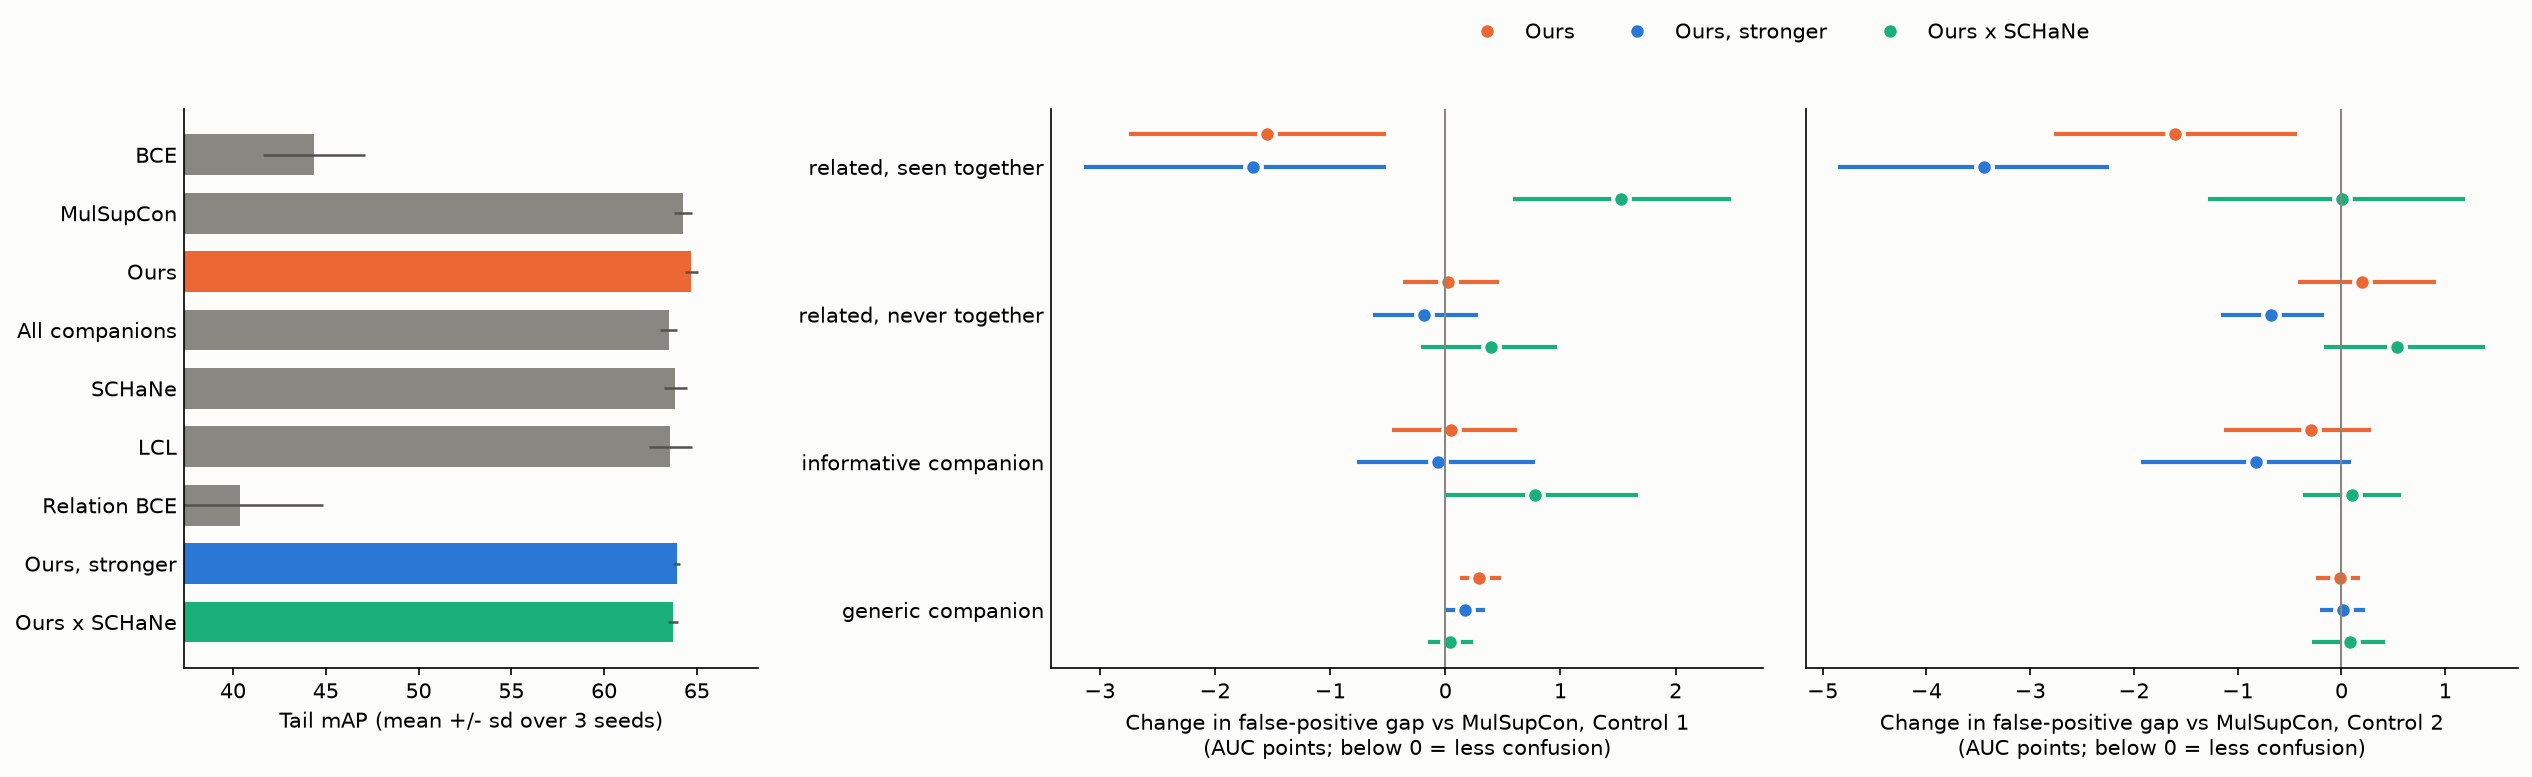

Saved coco_mlt\contrastive\round2.png


In [13]:
SURFACE, MUTED, INK = "#fcfcfb", "#898781", "#52514e"
COLOR = {"ours": "#eb6834", "ours_strong": "#2a78d6", "ours_schane": "#1baf7a"}
fig = plt.figure(figsize=(17, 5.4), facecolor=SURFACE)
# fixed margins: room for the variant names (left) and the type names
# (between the first and second panel); the two right panels share y
gs_left = fig.add_gridspec(1, 1, left=0.075, right=0.30, bottom=0.17, top=0.86)
gs_right = fig.add_gridspec(1, 2, left=0.415, right=0.99, bottom=0.17,
                            top=0.86, wspace=0.06)
ax0 = fig.add_subplot(gs_left[0])
vals = [[100 * np.nanmean(a[TAIL]) for a in AP_SEED[k]] for k in ORDER]
y = np.arange(len(ORDER))[::-1]
ax0.barh(y, [np.mean(v) for v in vals], height=0.7,
         xerr=[np.std(v, ddof=1) for v in vals],
         color=[COLOR.get(k, MUTED) for k in ORDER],
         error_kw=dict(ecolor=INK, lw=1.2))
ax0.set_yticks(y)
ax0.set_yticklabels([SHORT[k] for k in ORDER])
ax0.set_xlabel("Tail mAP (mean +/- sd over 3 seeds)")
ax0.set_xlim(left=max(0, min(np.mean(v) for v in vals) - 3))
ax1 = fig.add_subplot(gs_right[0])
axes_r = (ax1, fig.add_subplot(gs_right[1], sharey=ax1))
axes_r[1].tick_params(labelleft=False)
ty = np.arange(len(TYPES))[::-1]
for i, ax in enumerate(axes_r):
    for off, key in zip((0.22, 0.0, -0.22), ("ours", "ours_strong", "ours_schane")):
        for j in range(len(TYPES)):
            m, lo, hi, _ = TYPE_CI[(key, "mulsupcon", i, j)]
            if not np.isfinite(m):
                continue
            ax.hlines(ty[j] + off, lo, hi, color=COLOR[key], lw=2)
            ax.plot(m, ty[j] + off, "o", color=COLOR[key], ms=8, mec=SURFACE,
                    mew=2, label=SHORT[key] if j == 0 else None)
    ax.axvline(0, color=MUTED, lw=1)
    ax.set_xlabel(f"Change in false-positive gap vs MulSupCon, Control {i + 1}\n"
                  f"(AUC points; below 0 = less confusion)")
axes_r[0].set_yticks(ty)
axes_r[0].set_yticklabels(TYPES)
handles, labels = axes_r[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, loc="upper center",
           bbox_to_anchor=(0.70, 0.99), ncol=3)
for a in (ax0, *axes_r):
    a.set_facecolor(SURFACE)
    for side in ("top", "right"):
        a.spines[side].set_visible(False)
    a.tick_params(axis="y", length=0)
FIG = os.path.join(OUT, "round2.png")
fig.savefig(FIG, dpi=150, bbox_inches="tight", facecolor=SURFACE)
plt.close(fig)
display(Image(filename=FIG))
print(f"Saved {FIG}")

## Step 11: save the results

In [14]:
results_table.to_csv(os.path.join(OUT, "results_round2.csv"), index=False)
type_levels.to_csv(os.path.join(OUT, "by_type_gaps.csv"), index=False)
type_changes.to_csv(os.path.join(OUT, "by_type_changes.csv"), index=False)
round2_table.to_csv(os.path.join(OUT, "round2_comparisons.csv"), index=False)
pd.DataFrame(selection_rows).to_csv(os.path.join(OUT, "selection_round2.csv"),
                                    index=False)
with open(os.path.join(OUT, "summary_round2.txt"), "w", encoding="utf-8") as f:
    f.write("\n".join(lines) + "\n\n" + results_table.to_string(index=False)
            + "\n\nBy relation type:\n" + type_changes.to_string(index=False)
            + "\n")
print("\n".join(lines))
print(f"\nSaved results_round2.csv, by_type_gaps.csv, by_type_changes.csv, "
      f"round2_comparisons.csv, selection_round2.csv and summary_round2.txt to "
      f"{os.path.abspath(OUT)}")

Ours with stronger weights (round 2) vs MulSupCon (exploratory): NOT SHOWN  (tail AP improved: False, higher tail mAP in 1 of 3 seeds; related-class gap reduced: True; head AP within 1 point: False)
Ours x SCHaNe weights (round 2) vs MulSupCon (exploratory): NOT SHOWN  (tail AP improved: False, higher tail mAP in 1 of 3 seeds; related-class gap reduced: False; head AP within 1 point: True)

Saved results_round2.csv, by_type_gaps.csv, by_type_changes.csv, round2_comparisons.csv, selection_round2.csv and summary_round2.txt to c:\Users\Admin\pilot-20261029T110719Z-1-001\coco_mlt\contrastive


## How to read the results

- **Step 8, "Ours vs MulSupCon":** if our method works as designed, the
  biggest drop should be for *related, seen together* (the type with
  the largest weight), smaller for *related, never together* and
  *informative companion*, and none for *generic companion* (not
  weighted). That pattern would support the mechanism even where the
  overall tail gain is small.
- **Step 8, "SCHaNe vs MulSupCon":** shows which types the generic
  hard-negative method makes worse.
- **Step 9** gives exploratory verdicts for the two new variants.

## Limitations

- Round 2 is exploratory: its ideas were chosen after seeing round 1,
  so its verdicts are weaker evidence than round 1's. Report every
  variant tried, and confirm any gain on a second dataset.
- Some types have few usable tail classes (Step 8 prints the numbers);
  intervals for those are wide.
- The type groups and the gaps use the same evaluation images as the
  diagnostics that motivated the method.
- Settings are chosen on one seed's dev results; three seeds in total.